<a href="https://colab.research.google.com/github/flexycode/Talosig_SY-26-27-CCADMACL_EXERCISES/blob/main/Exercises/Exercise_1_Talosig.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXERCISE 1 — Generative vs Discriminative Models

You are helping a team of biologists in Antarctica. They measure penguins in the field and want to know **which species each penguin is**: **Adelie** or **Chinstrap**.

**Goal:** Predict the species of a penguin using its body measurements.

This is a **supervised learning** problem: we have features (`BillLength`, `BillDepth`, `FlipperLength`, `BodyMass`, `Sex`) and a label (`Species`). You will train two kinds of classifiers and **visualize** how each one thinks:

- **Part 1 — Generative (Naive Bayes):** learns the **joint probability** of the features and the label. It learns the *shape* of each group (Adelie / Chinstrap).
- **Part 2 — Discriminative (Logistic Regression):** learns the **conditional probability** of the label given the features **directly**. It learns a *boundary* that separates the groups.

*Tip: the Demo notebook (`Demo_Generative&Discriminative.ipynb`) follows the same steps with a different dataset.*

Dataset: https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data

---

## Objectives

By the end of this exercise, you should be able to:

1. Explain the difference between a **generative** model (learns the joint probability) and a **discriminative** model (learns the conditional probability directly).
2. Train a **Naive Bayes** model (generative) and a **Logistic Regression** model (discriminative) using scikit-learn.
3. Make predictions on test data and measure **accuracy**.
4. **Visualize** what each model learned: the *shape of each group* for the generative model, and the *decision boundary* for the discriminative model.
5. Compare the two models.

## Expected Outcomes

When you finish, your notebook should have:

| Section | Expected outcome |
|---|---|
| 3 & 6 | Two trained models: `nb` (Naive Bayes) and `logreg` (Logistic Regression) |
| 4 & 7 | Test accuracy printed for each model: about **0.95** for Naive Bayes and about **1.00** for Logistic Regression |
| 5 | A plot with **two separate filled shapes**: a blue one around the Adelie penguins (shorter bills) and a red one around the Chinstrap penguins (longer bills) |
| 8 | A plot with the same dots and **one gray line** (the decision boundary) between the two species |
| 9 | A comparison table and bar chart of both models |

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

In [2]:
# Downloads the dataset from Kaggle automatically (no API key needed)
datasetpath = kagglehub.dataset_download("parulpandey/palmer-archipelago-antarctica-penguin-data")
dataseturl = glob.glob(os.path.join(datasetpath, "**", "penguins_size.csv"), recursive=True)[0]

## 1. Load the Dataset

Run the cell below to load the data. Each row is one penguin.

In [3]:
df = pd.read_csv(dataseturl)
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 2. Prepare the Data

The cell below keeps only the **Adelie** and **Chinstrap** penguins, removes rows with missing values, and prepares these columns:

| Column | Meaning | Encoding |
|---|---|---|
| `BillLength` | length of the bill (beak) *(feature)* | mm |
| `BillDepth` | depth (thickness) of the bill *(feature)* | mm |
| `FlipperLength` | length of the flipper (wing) *(feature)* | mm |
| `BodyMass` | weight of the penguin *(feature)* | kg |
| `Sex` | sex of the penguin *(feature)* | female = 0, male = 1 |
| `Species` | species of the penguin *(label)* | 0 = Adelie, 1 = Chinstrap |

It splits the data into **80% training** and **20% testing**:

- Use `X_train`, `y_train` to **train** the models.
- Use `X_test`, `y_test` to **test** the models.

It also creates things you will need for the visualizations:

- `grid`, `xx`, `yy` — a grid of `BillLength` / `BillDepth` points that covers the whole plot.
- `colors` and `labels` — the color and legend name of each group: `0` = Adelie (blue), `1` = Chinstrap (red).

In [4]:
penguins = df[df["species"].isin(["Adelie", "Chinstrap"]) & df["sex"].isin(["MALE", "FEMALE"])].dropna()

data = pd.DataFrame({
    "BillLength":    penguins["culmen_length_mm"],
    "BillDepth":     penguins["culmen_depth_mm"],
    "FlipperLength": penguins["flipper_length_mm"],
    "BodyMass":      penguins["body_mass_g"] / 1000,                    # grams -> kg
    "Sex":           (penguins["sex"] == "MALE").astype(int),          # female = 0, male = 1
    "Species":       (penguins["species"] == "Chinstrap").astype(int), # 0 = Adelie, 1 = Chinstrap
})

features = ["BillLength", "BillDepth", "FlipperLength", "BodyMass", "Sex"]

train, test = train_test_split(data, test_size=0.2, stratify=data["Species"], random_state=42)

X_train, y_train = train[features], train["Species"]
X_test,  y_test  = test[features],  test["Species"]

# ---- For the visualizations ----
# Grid of (BillLength, BillDepth) points that covers the whole plot
xx, yy = np.meshgrid(np.linspace(30, 60, 300), np.linspace(14, 23, 300))
grid = pd.DataFrame({"BillLength": xx.ravel(), "BillDepth": yy.ravel()})

colors = {0: "#0077b6", 1: "#e63946"}
labels = {0: "Adelie", 1: "Chinstrap"}

print("Train:", X_train.shape, " Test:", X_test.shape)
X_train.head()

Train: (171, 5)  Test: (43, 5)


,BillLength,BillDepth,FlipperLength,BodyMass,Sex
179,49.5,19.0,200.0,3.800,1
134,38.1,17.6,187.0,3.425,0
41,40.8,18.4,195.0,3.900,1
29,40.5,18.9,180.0,3.950,1
44,37.0,16.9,185.0,3.000,0


# PART 1 — GENERATIVE: Naive Bayes `(25 pts)`

A generative model learns **how each group's data is spread out**: what Adelie penguins usually look like, and what Chinstrap penguins usually look like.
From this it gets the **joint probability** of the features and the label, then uses **Bayes' rule** to classify.

We will use `GaussianNB`, a Naive Bayes model for numeric features.

## 3. Train the Model `(8 pts)`

1. Create a `GaussianNB()` model and name it `nb`. `(4 pts)`
2. Train it on `X_train` and `y_train`. `(4 pts)`

*Hint: `model.fit(X, y)`*

In [5]:
# Generative model: learns how the features are spread out inside each group
nb = GaussianNB()
nb.fit(X_train, y_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[117., 54.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.68,0.32]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,5.196e-08
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['BillLength','BillDepth','FlipperLength','BodyMass','Sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 5)","[[ 38.8 , 18.42,190.52, 3.71, 0.5 ], [ 48.88, 18.48,195.89, 3.75, 0.54]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 5)","[[ 6.07, 1.47,42.15, 0.18, 0.25], [11.17, 1.12,53.51, 0.12, 0.25]]"


## 4. Predict and Evaluate `(7 pts)`

1. Predict the labels of `X_test` and save them as `pred_nb`. `(3 pts)`
2. Compute the accuracy and save it as `acc_nb`. Print it. `(4 pts)`

*Hint: `model.predict(X)` and `accuracy_score(y_true, y_pred)`*

In [6]:
pred_nb = nb.predict(X_test)

acc_nb = accuracy_score(y_test, pred_nb)
print("Naive Bayes test accuracy:", round(acc_nb, 4))


Naive Bayes test accuracy: 0.9535


## 5. Visualize the Generative Model `(10 pts)`

Show the **shape of each group** (Adelie / Chinstrap) that Naive Bayes learned.

A plot only has 2 axes, but `nb` uses 5 features. So for the plot, train a small copy of the model that uses only `BillLength` (x-axis) and `BillDepth` (y-axis).

1. Create another `GaussianNB()` named `nb_2d` and train it on `X_train[["BillLength", "BillDepth"]]` and `y_train`. `(2 pts)`
2. Compute the **joint probability** of every point in `grid` using `nb_2d` and save it as `joint_nb`. `(2 pts)`
3. For each group, draw a **filled shape** and an **outline** using `joint_nb`, in that group's color. `(3 pts)`
4. On the same plot, draw the training penguins as dots, using `colors` and `labels`. Add axis labels, a title and a legend. `(3 pts)`

*Hints:*
- *`np.exp(nb_2d.predict_joint_log_proba(grid))` gives the joint probability. Column `0` = Adelie, column `1` = Chinstrap.*
- *For each group `k`: `z = joint_nb[:, k].reshape(xx.shape)`, then*
  - *`ax.contourf(xx, yy, z, levels=[z.max() * 0.1, z.max()], colors=colors[k], alpha=0.25)`*
  - *`ax.contour(xx, yy, z, levels=[z.max() * 0.1], colors=colors[k], linewidths=2)`*
- *`ax.scatter(x, y, c=colors[k], edgecolors="white", s=55, label=labels[k])`*

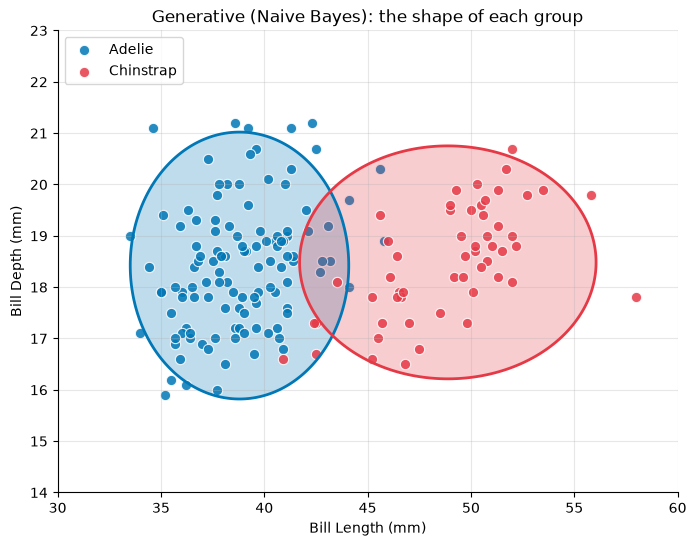

In [7]:
# 1. Small copy of the model with only BillLength and BillDepth, so we can draw it
nb_2d = GaussianNB()
nb_2d.fit(X_train[["BillLength", "BillDepth"]], y_train)

# 2. Joint probability of every grid point, for each group
joint_nb = np.exp(nb_2d.predict_joint_log_proba(grid))

fig, ax = plt.subplots(figsize=(8, 6))
for k in [0, 1]:
    # 3. Filled shape + outline = where the model thinks group k is
    z = joint_nb[:, k].reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[z.max() * 0.1, z.max()], colors=colors[k], alpha=0.25)
    ax.contour(xx, yy, z, levels=[z.max() * 0.1], colors=colors[k], linewidths=2)

    # 4. The penguins of group k
    ax.scatter(X_train.loc[y_train == k, "BillLength"], X_train.loc[y_train == k, "BillDepth"],
               c=colors[k], edgecolors="white", linewidths=0.8, s=55, alpha=0.85, label=labels[k])

ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.set_title("Generative (Naive Bayes): the shape of each group")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.show()


# PART 2 — DISCRIMINATIVE: Logistic Regression `(25 pts)`

A discriminative model does **not** learn how each group's data is spread out.
It learns the **conditional probability** of the species given the features **directly**, and draws a **decision boundary** between the groups.

We will use `LogisticRegression`.

## 6. Train the Model `(8 pts)`

1. Create a `LogisticRegression(max_iter=1000)` model and name it `logreg`. `(4 pts)`
2. Train it on `X_train` and `y_train`. `(4 pts)`

In [8]:
# Discriminative model: learns the conditional probability directly
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

## 7. Predict and Evaluate `(7 pts)`

1. Predict the labels of `X_test` and save them as `pred_lr`. `(3 pts)`
2. Compute the accuracy and save it as `acc_lr`. Print it. `(4 pts)`

In [9]:
pred_lr = logreg.predict(X_test)

acc_lr = accuracy_score(y_test, pred_lr)
print("Logistic Regression test accuracy:", round(acc_lr, 4))


Logistic Regression test accuracy: 1.0


## 8. Visualize the Discriminative Model `(10 pts)`

Show the **decision boundary** that Logistic Regression learned between Adelie and Chinstrap.

Same as Section 5: for the plot, train a small copy of the model that uses only `BillLength` and `BillDepth`.

1. Create another `LogisticRegression(max_iter=1000)` named `logreg_2d` and train it on `X_train[["BillLength", "BillDepth"]]` and `y_train`. `(2 pts)`
2. Compute the **conditional probability** of Chinstrap for every point in `grid` using `logreg_2d` and save it as `cond_lr`. `(2 pts)`
3. Draw the training penguins as dots, same as Section 5 (no shapes). `(3 pts)`
4. On the same plot, draw the **decision boundary**: the line where `cond_lr` is 0.5. Add axis labels, a title and a legend. `(3 pts)`

*Hints:*
- *`logreg_2d.predict_proba(grid)[:, 1]` gives the probability of Chinstrap.*
- *`ax.contour(xx, yy, cond_lr.reshape(xx.shape), levels=[0.5], colors="dimgray", linewidths=3)`*

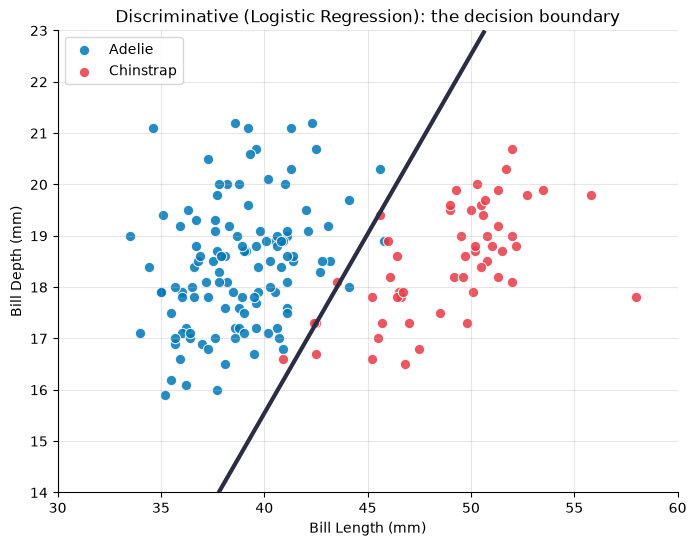

In [10]:
# 1. Small copy of the model with only BillLength and BillDepth, so we can draw it
logreg_2d = LogisticRegression(max_iter=1000)
logreg_2d.fit(X_train[["BillLength", "BillDepth"]], y_train)

# 2. Conditional probability of Chinstrap for every grid point
cond_lr = logreg_2d.predict_proba(grid)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

# 3. The penguins of each group
for k in [0, 1]:
    ax.scatter(X_train.loc[y_train == k, "BillLength"], X_train.loc[y_train == k, "BillDepth"],
               c=colors[k], edgecolors="white", linewidths=0.8, s=55, alpha=0.85, label=labels[k])

# 4. Decision boundary = where the model is 50/50
ax.contour(xx, yy, cond_lr.reshape(xx.shape), levels=[0.5], colors="#2b2d42", linewidths=3)

ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.set_title("Discriminative (Logistic Regression): the decision boundary")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.show()


## 9. Compare the Models

Run the cell below to compare your two models.

,Model,Type,Learns,Test Accuracy
0,Naive Bayes (GaussianNB),Generative,Joint probability,0.9535
1,Logistic Regression,Discriminative,Conditional probability,1.0000


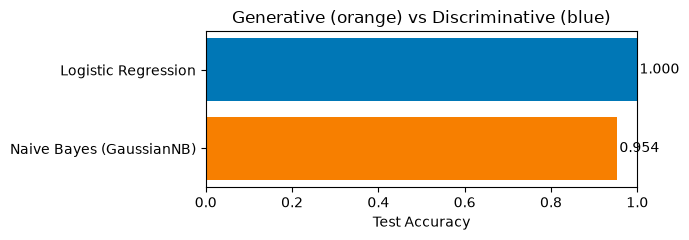

In [11]:
# Compares the generative model (Part 1) and the discriminative model (Part 2)
comparison = pd.DataFrame({
    "Model": ["Naive Bayes (GaussianNB)", "Logistic Regression"],
    "Type":  ["Generative", "Discriminative"],
    "Learns": ["Joint probability", "Conditional probability"],
    "Test Accuracy": [acc_nb, acc_lr],
}).round(4)
display(comparison)

bar_colors = comparison["Type"].map({"Generative": "#f77f00", "Discriminative": "#0077b6"})
plt.figure(figsize=(7, 2.5))
plt.barh(comparison["Model"], comparison["Test Accuracy"], color=bar_colors)
for i, v in enumerate(comparison["Test Accuracy"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0, 1)
plt.xlabel("Test Accuracy")
plt.title("Generative (orange) vs Discriminative (blue)")
plt.tight_layout()
plt.show()